In [2]:
import numpy as np
import scipy as sc
import matplotlib.pyplot as plt

In [3]:
# part c

# params
T = 500
lambd = 12
mu = 3
rho = lambd/mu

In [ ]:
# Gillespie Simulation from Wikipedia
# 1. Initialize at time t=t_0 and state x=x_0
# 2. Evaluate each propsenity a_j(x) and their total a_0(x)
# 3. Generate the waiting time tau and select the next reaction j
# 4. Advance the time according to t <- t+ tau
# 5. Update the state according to x <- x + v_j where v_j is the state-change vector associated with reaction j
# 6. Record the state if required and repeat until the chosen stopping condition is reached

In [ ]:
# do the actual gillespie simulation

t = 0 #t_0
n = 0 #x_0
time_in_state = [] # to track to take mean of later
states_hist = [] # to track again for later

while t < T: # stopping condition
    rate = lambd + n * mu # rate based on current state
    tau = np.random.exponential(1/rate)
    if t + tau > T: # if we would be going over the stopping time
        tau = T - t # set tau to be the time it takes to get to 500 from current time so that the holding times sum to exactly 500
        time_in_state.append(tau)
        states_hist.append(n)
        break
    time_in_state.append(tau) # otherwise append it
    states_hist.append(n)
    t += tau # advance
    if np.random.uniform(0,1) < lambd/rate: # update state based on whether go up one or down one
        n += 1
    else:
        n -= 1

In [ ]:
states_arr = np.array(states_hist)
times_arr = np.array(time_in_state)

# simulation stuff
sim_probs = np.bincount(states_arr, weights=times_arr) / T # number of times visited each state weighted by time spent to give probabilities (when divided by T)
states = np.arange(len(sim_probs)) # just to get a chill list of all states visited

# now to compare with the theory - stationary distribution Poisson given
theory_probs = sc.stats.poisson.pmf(states, rho)

diffs = np.abs(sim_probs - theory_probs)
max_diff = np.max(diffs)
max_diff_state = states[np.argmax(diffs)]

time_avg = np.sum(states * sim_probs)

print(f'Largest Difference {max_diff:.5f} at state n={max_diff_state}')
print(f'Time average of X_t: {time_avg:.5f} vs theoretical rho: {rho:.5f}')



Largest Difference 0.00649 at state n=3
Time average of X_t: 3.96906 vs theoretical rho: 4.00000


(-1.0, 14.0)

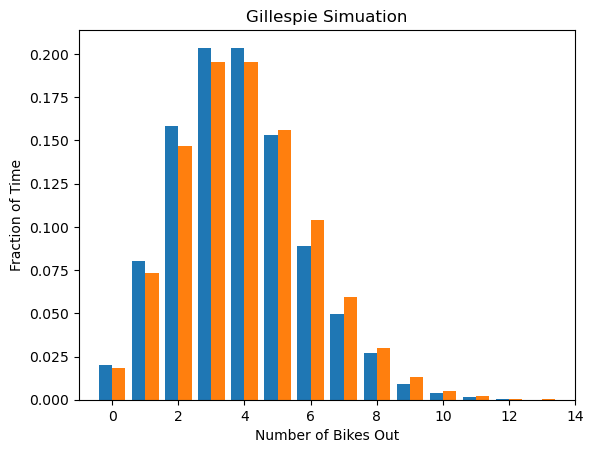

In [ ]:
# bar plot
width = 0.4 #just so everything fits pretty
plt.bar(states - width/2, sim_probs, width, label='Simulated Fraction of Time')
plt.bar(states + width/2, theory_probs, width, label='Theoretical Poisson')
plt.xlabel('Number of Bikes Out')
plt.ylabel('Fraction of Time')
plt.title('Gillespie Simuation')
plt.xlim([-1, 14])